<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/project/Project3_Starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA Project Week — Option 3: How Sure Are We of a Psychometric Curve?**

**Question.** How precisely can we estimate how strongly a mouse's choices depend on the contrast difference, and its bias?

**Minimum result.** A logistic psychometric curve for session 11, fitted by gradient descent, with a Bayesian 95% credible interval for its slope and bias, compared with a bootstrap interval.

**Lessons to revisit.** 16 (conditional probability), 18 (binomial likelihood), 12 (gradient descent), 19 (Bayes), 20 (bootstrap).

**Data.** `steinmetz_s11_lederberg.npz` (and `steinmetz_s25_radnitz.npz` for the stretch goal). Steinmetz et al. (2019), *Nature* 576:266–273; subsets of the Neuromatch Academy release; the original data are released under CC0.

**How to use this notebook.** Run it top to bottom: it loads the data, shows it, and works one first step for you. Cells marked `# TODO` are yours; each is followed by a check cell that prints *TODO* until your code sets the variables it names, then tests their shapes and simple sanity conditions. Add your own cells freely, but keep every array described by its shape and units.

### Set-up

In [1]:
# SETUP -- run first.
import os, urllib.request
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']   # Okabe-Ito, as in the lessons
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': False, 'figure.dpi': 100})
DATA_URL = 'https://raw.githubusercontent.com/peter-adepoju/math-neuro-ml/51d88220064023b5d3240c39e19b07acc7896f44/data/'

def load(name):
    # A local copy (here, or in the repository's data/ folder) first; otherwise download it from the pinned commit.
    for candidate in [name, os.path.join('..', 'data', name), os.path.join('..', '..', 'data', name)]:
        if os.path.exists(candidate):
            return np.load(candidate)
    urllib.request.urlretrieve(DATA_URL + name, name)
    return np.load(name)

def todo(*values):
    # True while any of the values is still None: the check cells below use it to wait for your code.
    return any(v is None for v in values)
print('Set-up complete.')

Set-up complete.


### Data tour

| Array | Shape | Meaning, units |
|---|---|---|
| `x` | (276,) | contrast difference on each turn trial, left minus right (unitless, −1 to 1) |
| `y` | (276,) | 1 = left turn, 0 = right turn |

The model is $P(\text{left} \mid x) = \sigma(b + s\,x)$ with $\sigma(u) = 1/(1 + e^{-u})$: $s$ is the sensitivity (slope) and $b$ the bias. Its negative log-likelihood is
$$\mathcal{L}(b, s) = -\sum_i \big[y_i \log p_i + (1 - y_i)\log(1 - p_i)\big].$$

x = -1.00:   0 left of  22
x = -0.75:   2 left of  24
x = -0.50:   5 left of  28
x = -0.25:   2 left of  24
x = +0.00:  29 left of  76
x = +0.25:  20 left of  24
x = +0.50:  36 left of  37
x = +0.75:  20 left of  20
x = +1.00:  21 left of  21


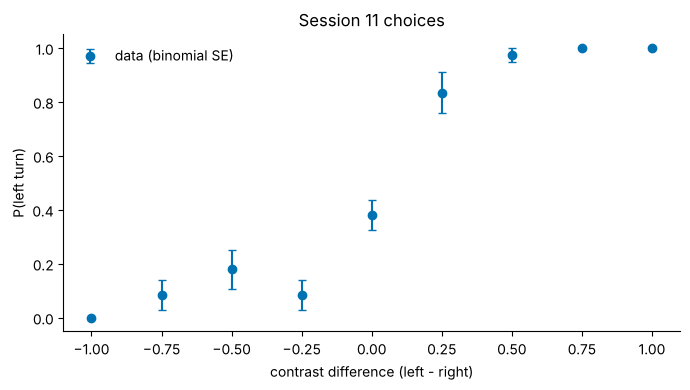

In [2]:
d = load('steinmetz_s11_lederberg.npz')
turn = d['response'] != 0
x = (d['contrast_left'] - d['contrast_right'])[turn]          # (276,) contrast difference
y = (d['response'][turn] == 1).astype(int)                   # (276,) 1 = left turn
levels = np.unique(x)
n_lev = np.array([np.sum(x == v) for v in levels]); k_lev = np.array([y[x == v].sum() for v in levels])
p_lev = k_lev / n_lev; se = np.sqrt(p_lev * (1 - p_lev) / n_lev)
for v, n, k in zip(levels, n_lev, k_lev):
    print(f"x = {v:+.2f}: {k:>3} left of {n:>3}")
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(levels, p_lev, yerr=se, fmt='o', color=PALETTE[0], capsize=3, label='data (binomial SE)')
ax.set_xlabel('contrast difference (left - right)'); ax.set_ylabel('P(left turn)'); ax.set_title('Session 11 choices'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### Worked first step: the negative log-likelihood and its gradient

In [3]:
sig = lambda u: 1 / (1 + np.exp(-u))
def nll(b, s):
    p = np.clip(sig(b + s * x), 1e-12, 1 - 1e-12)
    return -np.sum(y * np.log(p) + (1 - y) * np.log(1 - p))
def grad(b, s):
    r = sig(b + s * x) - y                                   # (276,) residuals
    return np.array([r.sum(), (r * x).sum()])
print("NLL at b = 0, s = 1:", round(nll(0, 1), 2), "  gradient:", np.round(grad(0, 1), 2))
h = 1e-5
print("central-difference check of the gradient:", round((nll(h, 1) - nll(-h, 1)) / (2 * h), 2), round((nll(0, 1 + h) - nll(0, 1 - h)) / (2 * h), 2))

NLL at b = 0, s = 1: 147.63   gradient: [  3.15 -33.68]
central-difference check of the gradient: 3.15 -33.68


In [4]:
# TODO 1 -- Fit (b, s) by gradient descent on nll (Lesson 12). Start at (0, 0), pick a step size that converges, stop when
# the gradient norm is below 1e-6 or after 100000 steps. Store b_hat, s_hat, and plot the fitted curve over the data.
b_hat = s_hat = None

In [5]:
if todo(b_hat, s_hat):
    print('TODO 1 not done yet.')
else:
    assert np.linalg.norm(grad(b_hat, s_hat)) < 1e-3, "the fit should sit where the gradient vanishes"
    print('Check 1 passed.')

TODO 1 not done yet.


In [6]:
# TODO 2 -- Posterior on a grid (Lesson 19). Flat prior on b in [-3, 3] and s in [0, 15] (grids of 301 and 301 points).
# Posterior proportional to exp(-nll). Store the posterior means post_b, post_s and the 95% credible intervals
# ci_b, ci_s (2.5th and 97.5th percentiles of each marginal).
post_b = post_s = ci_b = ci_s = None

In [7]:
if todo(post_b, post_s, ci_b, ci_s):
    print('TODO 2 not done yet.')
else:
    assert ci_b[0] < post_b < ci_b[1] and ci_s[0] < post_s < ci_s[1]
    print('Check 2 passed.')

TODO 2 not done yet.


In [8]:
# TODO 3 -- Bootstrap (Lesson 20). Resample the 276 trials with replacement 500 times, refit (b, s) each time (you may
# use scipy.optimize.minimize on nll, rewritten to take the resampled data), and store the 95% percentile intervals
# boot_ci_b and boot_ci_s. Compare them with the credible intervals.
boot_ci_b = boot_ci_s = None

In [9]:
if todo(boot_ci_b, boot_ci_s):
    print('TODO 3 not done yet.')
else:
    assert boot_ci_b[0] < boot_ci_b[1] and boot_ci_s[0] < boot_ci_s[1]
    print('Check 3 passed.')

TODO 3 not done yet.


### Before the talk
- A flat prior on a bounded grid is a choice: say what happens if the bounds change.
- Trials are not independent in a real session (engagement drifts): the stretch goal tests the first against the second half.
- Stretch: compare the two mice (`steinmetz_s25_radnitz.npz`).